# 06 · The improved method against the deployed one at 100 m

**Question:** how much better is the improved method (notebook 05's blend) than the forecast the platform runs now (`main`'s backend), is the gain real, and what would the platform change to run it?

Both are run with the platform's own code on four windows, three seeds each: backtest 2021 → 2022 → 2023, validation 2022 → 2023 → 2024, test 2023 → 2024 → 2025, and the **fresh window** 2020 → 2021 → 2022. The improved method was chosen on validation and confirmed on test and backtest (notebook 05); the fresh window was used by no choice, so it gives the fair estimate of the gain (Cawley & Talbot 2010). Each forecast is placed with `main`'s allocator, with the platform's projected amount (as users get it) and with the observed amount (to compare only where change is placed). Runs: `scripts/run04.py`, `run05*.py`, `run06.py`; code: `scripts/improved100.py`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import improved100 as I
M, D = I.M, I.D
C, G, H = D.C, D.G, D.C.H

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30, "display.width", 200)
S = I.scores()
summary = (S.groupby(["phase", "demand", "method"])
           .agg(mean=("FoM", "mean"), spread=("FoM", lambda v: v.max() - v.min()), seeds=("FoM", "size"),
                new=("new-change FoM", "mean"), random=("random FoM", "mean")))
print(f"{len(S)} scores; main's own figure_of_merit agrees with ours within {(S['FoM'] - S['platform FoM']).abs().max():.3f} points")

68 scores; main's own figure_of_merit agrees with ours within 0.005 points


## 1 · The two methods

| | Deployed (`main`'s backend) | Improved (notebook 05's blend) | Source |
|---|---|---|---|
| Transitions modelled | every transition with ≥ 10 samples | Random Forests for transitions with ≥ 1,000 changed cells; the regression also gives a map for the rarer transitions in its sample (28 maps in the test window, 23 with both), which keep its map alone | Thanh Noi & Kappas (2018) |
| Clouds (Esri class 10) | a land-cover class | no data | Karra et al. (2021) |
| Training sample | changed and unchanged cells at random | changes that touch an existing patch of the destination class (`main`'s Expander sample) | Soares-Filho et al. (2002) |
| Predictors | the 12 of `main` | the 12, plus the share of the destination class within 5 cells (500 m) | Verburg et al. (2002, 2004) |
| Models | one Random Forest per transition | the same Random Forests, and one logistic regression on each cell's 3 × 3 window of classes and predictors (MOLUSCE 5.1's) | NextGIS (2025); Verburg et al. (2004) |
| Suitability | the forest's probability | per transition, the two maps as ranks among the start-class cells, averaged with equal weights | Clemen (1989) |
| Amount of change | trend per transition, its form chosen by AICc (`run_change_analysis`) | the same | Burnham & Anderson (2002); other amount rules: notebook 05, section 6 |
| Allocation | each transition's amount to its most suitable cells, largest transition first (`run_allocation_simulation`) | the same | Pontius et al. (2001); Eastman et al. (1995) |

Both use maps and predictors up to the forecast's start year only. The amount and the allocation are `main`'s and the same in both. The amount is a trend per transition whose form is chosen by AICc (Burnham & Anderson 2002). Each transition's amount goes to its most suitable cells, as in GEOMOD (Pontius et al. 2001); where transitions compete for a cell, `main` serves the largest first, a simpler form of the multi-objective land allocation of Eastman et al. (1995).

## 2 · Scores in every window

Mean of three seeds. The gain counts if it is larger than the larger of the two seed spreads (Bouthillier et al. 2021); random is the same forecast's changes placed at random among the cells of each start class (Pontius et al. 2004).

In [2]:
rows = []
for phase in I.WINDOWS:
    for demand in ("projected", "observed"):
        d, b = summary.loc[(phase, demand, "backend")], summary.loc[(phase, demand, "blend")]
        gain = b["mean"] - d["mean"]
        rows.append({"window": phase, "amount": demand, "deployed": d["mean"], "deployed spread": d["spread"],
                     "improved": b["mean"], "improved spread": b["spread"], "gain": gain,
                     "gain > spread": "yes" if gain > max(d["spread"], b["spread"]) else "no",
                     "improved ÷ random": b["mean"] / b["random"]})
main_table = pd.DataFrame(rows).set_index(["window", "amount"])
C.save("06_scores.csv", main_table)
main_table.round(2)

deployed  deployed spread  improved  improved spread  gain gain > spread  improved ÷ random
window     amount                                                                                                
backtest   projected     13.73             0.24     16.10             0.04  2.37           yes               3.13
           observed      14.18             0.19     16.85             0.01  2.68           yes               3.19
validation projected     12.33             0.09     15.08             0.17  2.74           yes               3.51
           observed      14.53             0.65     18.01             0.21  3.48           yes               3.51
test       projected     12.73             0.30     15.26             0.19  2.53           yes               2.51
           observed      17.31             0.21     20.01             0.18  2.71           yes               2.33
fresh      projected     13.51             0.21     16.29             0.22  2.77           yes               3.59
           observed      16.04             0.30     19.76             0.29  3.72           yes               3.73

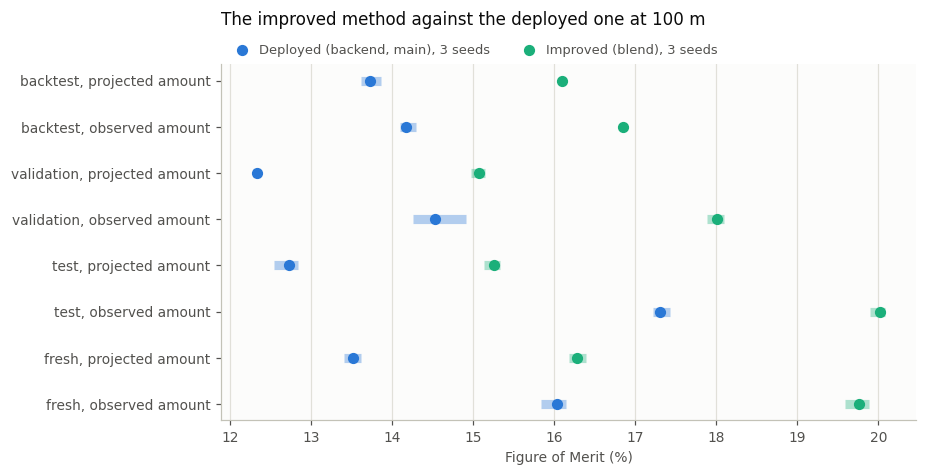

In [3]:
rows_ = list(main_table.index)[::-1]
y = np.arange(len(rows_))
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for method, colour in (("backend", H.SERIES[0]), ("blend", H.SERIES[2])):
    sel = [S[(S.method == method) & (S.phase == w) & (S.demand == d)]["FoM"] for w, d in rows_]
    ax.hlines(y, [s.min() for s in sel], [s.max() for s in sel], color=colour, linewidth=6, alpha=0.35, zorder=1)
    ax.scatter([s.mean() for s in sel], y, s=40, color=colour, zorder=3, label=f"{I.LABELS[method]}, 3 seeds")
ax.set_yticks(y, [f"{w}, {d} amount" for w, d in rows_])
ax.set_xlabel("Figure of Merit (%)", color=H.INK_2)
H.style_axes(ax)
ax.set_title("The improved method against the deployed one at 100 m", loc="left", color=H.INK, fontsize=11, pad=26)
ax.legend(frameon=False, fontsize=8.5, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, labelcolor=H.INK_2,
          handletextpad=0.3, borderaxespad=0.2)
plt.tight_layout(); plt.show()

**Reading:**

* **The improved method beats the deployed one in every window, with both amounts:** by 2.4–2.8 points as the platform runs it (projected amount; 12.3–13.7 % → 15.1–16.3 %, about a fifth higher), and by 2.7–3.7 points with the observed amount. Every gain is 5 to 16 times the larger seed spread (at most 0.65).
* **On the fresh window, which no choice used, the gain is as large as anywhere:** +2.8 points as it runs (13.51 → 16.29 %) and +3.7 with the observed amount (16.04 → 19.76 %). So the gain does not come from choosing on the same windows it is reported on.
* **Both beat random placement;** the improved method scores 2.3–3.7 times random.
* **Over all of Guinea** (test window, observed amount, seed 42) the improved method has 118,000 more hits, 113,000 fewer misses and 114,000 fewer false alarms than the deployed one, with the same number of changed cells.

## 3 · The weight check

The blend gives the document's map and the regression's map equal weight (Clemen 1989: equal weights are hard to beat unless the data say clearly otherwise). Here the document's map is weighted 0.25 and 0.75 instead, with the regression taking the rest: three seeds on the validation window, where a choice would be made, and seed 42 on test and backtest.

In [4]:
rows = []
for method, w in M.WEIGHTS.items():
    for phase in ("validation", "test", "backtest"):
        for demand in ("observed", "projected"):
            v = S[(S.method == method) & (S.phase == phase) & (S.demand == demand)]
            seed42 = v[v.seed == 42]["FoM"]
            rows.append({"document's weight": w, "window": phase, "amount": demand,
                         "FoM, seed 42": seed42.iloc[0] if len(seed42) else np.nan,
                         "FoM, mean of 3 seeds": v["FoM"].mean() if len(v) == 3 else np.nan,
                         "seed spread": v["FoM"].max() - v["FoM"].min() if len(v) == 3 else np.nan})
weights = pd.DataFrame(rows).pivot_table(index=["window", "amount"], columns="document's weight",
                                         values=["FoM, mean of 3 seeds", "FoM, seed 42"])
weights = weights.reindex(["validation", "test", "backtest"], level="window")
C.save("06_weights.csv", weights)
weights.round(2)

FoM, mean of 3 seeds               FoM, seed 42              
document's weight                    0.25   0.50   0.75         0.25   0.50   0.75
window     amount                                                                 
validation observed                 18.18  18.01  17.33        18.12  17.88  17.13
           projected                15.20  15.08  14.55        15.15  14.98  14.41
test       observed                   NaN  20.01    NaN        20.07  19.90  19.47
           projected                  NaN  15.26    NaN        15.27  15.14  14.81
backtest   observed                   NaN  16.85    NaN        17.22  16.86  16.23
           projected                  NaN  16.10    NaN        16.48  16.12  15.52

**Reading:**

* **Equal weights are kept.** On validation, three seeds, the document's weight 0.25 scores 18.18 % against 18.01 % for equal weights: a gain of 0.17, within the seed spread (0.21). Weight 0.75 scores 0.7 lower (17.33 %). With the projected amount: 15.20, 15.08 and 14.55 %.
* **On test and backtest (seed 42) the order is the same:** 0.25 is level or a little higher (+0.17 on test, +0.36 on backtest, observed amount), 0.75 lower by 0.4–0.8. More weight on the regression does not hurt, more on the document's map does; but where the choice is made the gain is no larger than the seed noise, so the simpler equal weights stay (Clemen 1989).

## 4 · Server cost

Minutes and peak memory per run on this device (mean over the windows: seed 42 for the deployed run, the three seeds for the improved one; peak memory is the whole process). The deployed run is `main`'s training, suitability, demand and allocation; the improved run is the document's models, the regression and the rank average, with `main`'s demand and allocation (about 2 minutes).

In [5]:
dep = D.stage_costs().query("method == 'backend'").groupby("phase")[["minutes", "peak_GB"]].agg({"minutes": "sum", "peak_GB": "max"})
imp = M.costs().query("method in ['document', 'lr', 'blend'] and phase in ['backtest', 'validation', 'test']")
imp = imp.groupby(["phase", "seed"]).agg(minutes=("minutes", "sum"), peak_GB=("peak_GB", "max"))
imp["minutes"] += 2                                                 # main's demand and allocation (notebook 04)
cost = pd.DataFrame({"minutes": [dep["minutes"].mean(), imp["minutes"].mean()],
                     "peak memory (GB), mean": [dep["peak_GB"].mean(), imp["peak_GB"].mean()],
                     "peak memory (GB), max": [dep["peak_GB"].max(), imp["peak_GB"].max()]},
                    index=[I.LABELS["backend"], I.LABELS["blend"]])
C.save("06_cost.csv", cost)
cost.round(1)

,minutes,"peak memory (GB), mean","peak memory (GB), max"
"Deployed (backend, main)",16.0,3.7,3.9
Improved (blend),15.8,6.4,8.0


**Reading:**

* **The improved run takes about as long as the deployed one,** about 16 minutes at 100 m here: fewer Random Forests (23 against 38 in the test window) leave room for the regression and the rank average.
* **It needs more memory:** 6–8 GB at peak against 3.4–3.9 GB, in the regression's step, which holds the 12 predictors as whole maps. That is too close to the server's limit to run as it is: the heavy worker stops a job at 80 % of its memory limit (about 9.6 GB), the platform loads its own data on top, and two land-use prediction jobs at 100 m have already been stopped for running out of memory (notebook 02). So the regression must read the predictors in blocks of rows, and the predictors must be written to their files one at a time (section 5, step 6).
* **Both stay inside the platform's 30-minute limit per land-use task** (`CELERY_TASK_TIME_LIMIT`, `main`), with room for a server slower than this laptop.

## 5 · What the platform would change

Suggestions only; nothing on the platform was changed. Function names are those of `main` (commit 6710b3d) unless marked as ours.

| Step | Change | Where |
|---|---|---|
| 1 | Leave clouds out and model only transitions with at least 1,000 changed cells (the document's rule) | `backend/landuse_api/tasks.py`, `run_training`: drop class 10 and filter the transitions before `training.train_transition_models` |
| 2 | Train each transition on the Expander sample, with the share of the destination class within 5 cells of the start map as a 13th predictor | `training.create_transition_dataset(..., mode="expander")` and `prediction._generate_single_suitability_map(..., model_type="expander")`, both already in `main`; the neighbourhood layer as ours (`deployed100._density_file`) |
| 3 | Fit one multinomial logistic regression on the 3 × 3 window of classes and the 12 predictors, and write one suitability map per transition | new; ours: `decisions100.run_lr` (scikit-learn, 50,000 random cells, 100 iterations) |
| 4 | Average the two maps per transition as ranks among the start-class cells | new; ours: `decisions100.run_blend`; the result is an ordinary suitability atlas, so `prediction.run_allocation_simulation` takes it unchanged |
| 5 | Keep the amount of change and the allocation | `change_analysis.run_change_analysis`, `prediction.run_allocation_simulation` |
| 6 | Write each predictor to its file as it is made, and let the regression read its inputs in blocks of rows | `data_loader.assemble_predictor_stack` / `prepare_predictor_files`; ours: `decisions100.run_lr` |

Step 6 is required, not optional (section 4): the regression holds the 12 predictors as whole maps (8 GB at peak here), and `main` holds them together once more when it builds them (5.3 GB, notebook 02). The scoring in `prediction._scoring_windows` already reads in blocks of rows.

## 6 · What this means

* **The improved method is about a fifth better than what the platform runs now:** 15.1–16.3 % against 12.3–13.7 % as it runs, +2.4–2.8 points in every window and +2.8 on the window no choice used; +2.7–3.7 with the observed amount.
* **The gain is real:** 5 to 16 times the seed spread, above random, and it holds on genuinely new change (+1.0–2.0 points; appendix).
* **Equal weights are kept** (section 3): more weight on the regression gains at most 0.4, within the seed noise where the choice is made; more on the document's map loses 0.4–0.8.
* **It takes the same time and about twice the memory;** to stay under the server's memory guard it must read its predictors in blocks (section 5, step 6).
* **The platform change is six steps** (section 5); the first two use functions already in `main`.
* **The amount of change is untouched:** the projection stays 18–27 % low (notebook 04), the largest error left; no rule built from past maps did better in every window (notebook 05, section 6).

**Sources**

* Bouthillier, X. et al. (2021). Accounting for variance in machine learning benchmarks. *Proceedings of Machine Learning and Systems* 3, 747–769.
* Burnham, K.P., Anderson, D.R. (2002). *Model Selection and Multimodel Inference*, 2nd ed. Springer.
* Cawley, G.C., Talbot, N.L.C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research* 11, 2079–2107.
* Clemen, R.T. (1989). Combining forecasts: a review and annotated bibliography. *International Journal of Forecasting* 5, 559–583.
* Eastman, J.R., Jin, W., Kyem, P.A.K., Toledano, J. (1995). Raster procedures for multi-criteria/multi-objective decisions. *Photogrammetric Engineering & Remote Sensing* 61(5), 539–547.
* Karra, K. et al. (2021). Global land use/land cover with Sentinel 2 and deep learning. *IGARSS 2021*, 4704–4707.
* NextGIS (2025). MOLUSCE 5.1, Modules for Land Use Change Evaluation, QGIS plugin (`algorithms/models/lr`). https://github.com/nextgis/molusce
* Pontius, R.G. Jr., Cornell, J.D., Hall, C.A.S. (2001). Modeling the spatial pattern of land-use change with GEOMOD2: application and validation for Costa Rica. *Agriculture, Ecosystems & Environment* 85, 191–203.
* Pontius, R.G. Jr., Huffaker, D., Denman, K. (2004). Useful techniques of validation for spatially explicit land-change models. *Ecological Modelling* 179, 445–461.
* Soares-Filho, B.S., Coutinho Cerqueira, G., Lopes Pennachin, C. (2002). DINAMICA — a stochastic cellular automata model designed to simulate the landscape dynamics in an Amazonian colonization frontier. *Ecological Modelling* 154, 217–235.
* Thanh Noi, P., Kappas, M. (2018). Comparison of Random Forest, k-Nearest Neighbor, and Support Vector Machine classifiers for land cover classification using Sentinel-2 imagery. *Sensors* 18, 18.
* Verburg, P.H. et al. (2002). Modeling the spatial dynamics of regional land use: the CLUE-S model. *Environmental Management* 30, 391–405.
* Verburg, P.H., de Nijs, T.C.M., Ritsema van Eck, J., Visser, H., de Jong, K. (2004). A method to analyse neighbourhood characteristics of land use patterns. *Computers, Environment and Urban Systems* 28, 667–690.

## Appendix · The flip-back check

Esri's maps flicker: they change 10–15 % of Guinea a year, and a quarter to two fifths of each year's change goes back the next year, mostly between trees and rangeland (notebook 01; `studies/dataset_checks`, notebook 01, section 4). Esri is still the map to use: it is the only annual 10 m land-cover map of Guinea up to 2025, Dynamic World is no more stable, and at 565 GLanCE points in Guinea it agrees with interpreters at 75 % (`studies/dataset_checks`, notebook 01, section 4, and notebook 02, section 2). So the flicker is stated with every result, not avoided.

A method could score by forecasting cells that return to a class they held before, which is flicker rather than land change. The check (README): the improved method must not find less genuinely new change than the deployed one. New change is change into a class the cell had not held in any map since 2017. Below, the new-change Figure of Merit (mean of three seeds) and, for seed 42 with the observed amount, how many hits are returns.

In [6]:
rows = []
for phase in I.WINDOWS:
    for demand in ("projected", "observed"):
        d, b = summary.loc[(phase, demand, "backend")], summary.loc[(phase, demand, "blend")]
        rows.append({"window": phase, "amount": demand, "deployed, new-change FoM": d["new"],
                     "improved, new-change FoM": b["new"], "gain": b["new"] - d["new"]})
flip = pd.DataFrame(rows).set_index(["window", "amount"])
ret = pd.DataFrame({(phase, I.LABELS[m]): I.returns(phase, m) for phase in I.WINDOWS for m in ("backend", "blend")}).T
ret["returns, % of hits"] = 100 * ret["returns"] / ret["hits"]
ret.index.names = ["window", "method"]
C.save("06_flip_back.csv", flip); C.save("06_returns.csv", ret)
display(flip.round(2))
ret.round(1)

deployed, new-change FoM  improved, new-change FoM  gain
window     amount                                                             
backtest   projected                      6.31                      7.94  1.63
           observed                       7.17                      9.13  1.96
validation projected                      5.28                      6.62  1.34
           observed                       7.73                      9.57  1.84
test       projected                      5.24                      6.86  1.63
           observed                       6.56                      8.14  1.58
fresh      projected                      6.58                      7.60  1.03
           observed                       9.95                     11.65  1.70

hits  returns     new  returns, % of hits
window     method                                                                
backtest   Deployed (backend, main)   648879   517015  131864                79.7
           Improved (blend)           749147   595526  153621                79.5
validation Deployed (backend, main)   667361   531823  135538                79.7
           Improved (blend)           812580   657060  155520                80.9
test       Deployed (backend, main)   927543   811451  116092                87.5
           Improved (blend)          1045566   916622  128944                87.7
fresh      Deployed (backend, main)   725440   533086  192354                73.5
           Improved (blend)           865459   661345  204114                76.4

**Reading:**

* **The improved method passes:** its new-change Figure of Merit is higher in every window and with both amounts, by 1.0–2.0 points.
* **Most hits of both methods are returns** (74–88 %), because most of Esri's change is flicker between classes a cell has held before (notebook 01). The improved method finds more of both kinds, including 12,000–22,000 more hits into a class new to the cell in each window; its share of returns is within 3 points of the deployed one's. Its gain is not flicker alone.